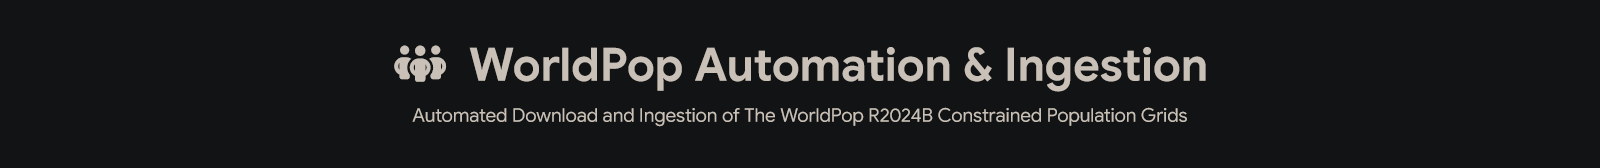

| | |
|:--|:--|
| **Authors** | Ali Rezaali & Parastoo Pilehforooshha |
| **Code Archive** | Zenodo · [10.5281/zenodo.22865045](https://doi.org/10.5281/zenodo.22865045) |
| **Data Archive** | Zenodo · [10.5281/zenodo.22723885](https://doi.org/10.5281/zenodo.22723885) |
| **Notebook Version** | 1.0.0 |
| **Runtime** | Google Colab (Python 3) |
| **Source-Data Licence** | WorldPop datasets are released under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) |

#### **How To Cite**

**UC4D (Code):**

> Rezaali, A., & Pilehforooshha, P. (2026). UC4D: Urban Climate 4D Data Cube Framework (Version 1.0) [Computer software]. Zenodo. https://doi.org/10.5281/zenodo.22865045

**UC4D (Dataset):**

> Rezaali, A., & Pilehforooshha, P. (2026). UC4D: Urban Climate 4D Data Cube (Version 1.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.22723885

**Note:** The data are redistributed WorldPop products, so please **also cite WorldPop** (Bondarenko et al., 2025; full references at the end of this notebook).

---

#### **Overview**

WorldPop's 2015–2030 gridded population products (release **R2024B**) are published as one GeoTIFF per country and year. This notebook turns them into analysis-ready **Google Earth Engine (GEE) assets** in a project-owned folder, with every step scripted so the result can be reproduced exactly.

| Step | Section | What Happens |
|:--:|:--|:--|
| 1 | §4 | Each city's spatial domain is intersected with a country-boundary layer in GEE to find which countries are needed. |
| 2 | §5 | The country GeoTIFFs for the chosen years are Downloaded from WorldPop (*resumable* and *size-checked*). |
| 3 | §6 | The rasters are uploaded to GEE with `geeup`, authenticated through your own signed-in browser session. |
| 4 | §7 | The notebook confirms the assets exist and reads back their pixel size and bands. |

#### **Products**

[1] **Spatial Distribution of Population**: Estimated number of people per pixel on a 3 arc-second grid (about 100 m at the equator, WGS84). The *constrained* variant places people only on pixels that WorldPop's settlement layers identify as built-up.

[2] **Age and Sex Population Structures** (Optional Bonus, Off by Default): Population by sex and age group (under 1 year, 1–4, then 5-year classes up to 90+). Enable with `IncludeAgeSex = True`; it is not used in the UC4D analysis.

#### **Resulting GEE Layout**

```text
projects/<project>/assets/UC4D/WorldPop/
└── <Country>/
    ├── Spatial-Distribution/<Year>/   ← <iso3>_pop_<Year>_CN_100m_R2024B_v1
    └── Age-Sex-Structures/<Year>/     ← <iso3>_<sex>_<ageGroup>_<Year>_CN_100m_R2024B_v1   (Optional)
```

> **Asset Ingestion & Version Control.** While a global WorldPop mosaic is now available in the Earth Engine community catalog, this custom ingestion pipeline was originally built prior to its release. It is retained as a standardized, reusable template for automating the ingestion of other external rasters into the UC4D asset tree with version control.

---

#### **Before You Begin**

[1] **An Earth Engine Project** with the Earth Engine API enabled, owned by the Google Account set in §2.

[2] **City Domain Assets** in that project, at the path given by `DomainAssetTemplate` (§2). They define each study area and drive the country detection.

[3] **`Countries.json`**, the country registry from the code archive. Place it at `MyDrive/UC4D/WorldPop/Countries.json` before running §3. Drive is mounted on Colab regardless of `StorageMode` because the registry is read from Drive.

[4] **A Desktop Browser With the Cookie-Editor Extension**, signed in to Earth Engine (explained in §6).

[5] **Disk Space.** §5 prints a size estimate before anything is Downloaded.

**Suggested Workflow:** run the whole notebook once with `RunMode = "Test"` (many cities, one year, uploads go to a separate `WorldPop/Test` folder). When it passes, set `RunMode = "Production"` and run again from the top. Files already Downloaded are reused.

---

#### **[1] Environment**

In [1]:
# ———————————————
# [1] Environment
# ———————————————

import os

import sys

import re

import glob

import json

import importlib.util

import subprocess

# geeup Is the Only Dependency Colab Doesn't Come With.

if importlib.util.find_spec("geeup") is None:

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "geeup"])

import datetime

import getpass

import platform

import shutil

import time

import warnings

import zipfile

from importlib import metadata

import ee

import pandas as pd

import geopandas as gpd

import requests

from IPython.display import display

from requests.adapters import HTTPAdapter

from tqdm.auto import tqdm

from urllib3.util.retry import Retry

warnings.filterwarnings( "ignore" , category = FutureWarning )

IsColab = "google.colab" in sys.modules

WorkDir = os.getcwd()

def PackageVersion(PackageName):

    try:

        return metadata.version(PackageName)

    except metadata.PackageNotFoundError:

        return "Not Installed"
    
import logging

logging.getLogger('google_auth_httplib2').setLevel(logging.ERROR)

# [1.1] Environment stamp

print("———————————")
print("Environment")
print("———————————")

print(f"\n  Run Started (UTC) : {datetime.datetime.now(datetime.timezone.utc):%Y-%m-%d %H:%M:%S}")

print(f"\n  Platform          : {'Google Colab' if IsColab else platform.platform()}")

print(f"\n  Python            : {platform.python_version()}")

for PackageName in ( "earthengine-api" , "geeup" , "geopandas" , "pandas" , "requests" ):

    print(f"\n  {PackageName:<18}: {PackageVersion(PackageName)}")

———————————
Environment
———————————

  Run Started (UTC) : 2026-11-03 19:37:58

  Platform          : Google Colab

  Python            : 3.13.18

  earthengine-api   : 1.7.39

  geeup             : 2.0.0

  geopandas         : 1.2.0

  pandas            : 2.2.3

  requests          : 2.32.4


---

#### **[2] Configuration**

| Setting | Purpose |
|:--|:--|
| `RunMode` | `"Test"` runs the test cities for a single year and uploads to `<GEEFolder>/Test`. `"Production"` runs the study cities for 2020–2025 and uploads to `<GEEFolder>`. |
| `CitiesByMode`, `YearsByMode` | City and year lists for each mode. City names must match the domain asset names (`<City>`). |
| `WorldPopVersion`, `DataVariant`, `Resolutions` | The WorldPop product to fetch. Fixed at R2024B, constrained, 100 m for UC4D. |
| `IncludeAgeSex` | Also download and ingest the age and sex structures. |
| `ChildAgeGroupMax`, `ElderlyAgeGroupMin` | Age groups kept at ingestion. WorldPop labels each age group by its lower bound, so `15` means ages 15–19. |
| `StorageMode` | `"Local"` is fast but disappears when the Colab runtime resets. `"Drive"` persists in your Google Drive. |
| `GEEProject`, `UserEmail`, `GEEFolder` | Where the assets are created and which account uploads them. |
| `CookieSource` | How the session cookies reach `geeup` (§6). |

In [2]:
# —————————————————
# [2] Configuration
# —————————————————

# [2.1] Run Mode

RunMode = "Test"  # "Test" → Main and Secondary Cities, One Year, Separate GEE Folder | "Production" → The Study Cities and Years

CitiesByMode = {

    "Production" : [ "Tehran" , "Singapore" ] ,

    "Test"       : [ "Tehran" , "Singapore" , "Amsterdam" , "Reykjavik" , "Cairo" ],

}

YearsByMode = {

    "Production" : list(range( 2020 , 2026 )) ,   # WorldPop Covers 2015–2030; UC4D Uses 2020–2025.

    "Test"       : [2021]                         # One Year Keeps the Test Download Small.

}

# [2.2] WorldPop Product

WorldPopVersion    = "R2024B"

DataVariant        = "constrained"                 # Only the Constrained Product Is Supported by This Notebook.

Resolutions        = ["100m"]                      # "100m" | "1km_ua" (UC4D Uses 100m Only)

IncludeAgeSex      = False                         # Bonus Dataset, NOT Used in the UC4D Analysis. Set True to Also Fetch It.

ChildAgeGroupMax   = 15                            # Age/Sex Filter, Applied at Ingestion: Keep Age Groups <= 15 …

ElderlyAgeGroupMin = 65                            # … and >= 65. Values Are the Lower Bound of WorldPop's Age Groups.

# [2.3] Storage

StorageMode          = "Drive"                     # "Local" → Colab Disk (Wiped When the Runtime Resets) | "Drive" → Google Drive

DriveFolder          = "UC4D/WorldPop"             # Relative to My Drive (No "MyDrive/" Prefix Needed).

# [2.4] Google Earth Engine

GEEProject           = "ee-alirezaali"

UserEmail            = "AliRezaaliGeo@gmail.com"   # The Google Account That Owns the GEE Project (Also Used by geeup).

GEEFolder            = "WorldPop"                  # Test Runs Are Written to a "/Test" Subfolder So Production Stays Clean.

DomainAssetTemplate  = "projects/" + GEEProject + "/assets/UC4D/Spatial-Domains/Complete-Domain/{City}"

CountryBoundaryAsset = "projects/sat-io/open-datasets/WORLD-BANK/WBGAD/WB_GAD_ADM0"

# [2.5] City Country Aliases

CityCountryAliases = {

    "Tehran"       : [ "Iran" ]                                         ,

    "Singapore"    : [ "Singapore" ]                                    ,

    "Amsterdam"    : [ "Netherlands (Kingdom of the)" , "Netherlands" ] ,

    "Reykjavik"    : [ "Iceland" ]                                      ,

    "Cairo"        : [ "Egypt" ]                                        ,

    "Mumbai"       : [ "India" ]                                        ,

    "Osaka"        : [ "Japan" ]                                        ,

    "Beijing"      : [ "China" ]                                        ,

    "Arequipa"     : [ "Peru" ]                                         ,

    "Marrakech"    : [ "Morocco" ]                                      ,

    "Perth"        : [ "Australia" ]                                    ,

    "CapeTown"     : [ "South Africa" ]                                 ,

    "Islamabad"    : [ "Pakistan" ]                                     ,

    "AddisAbaba"   : [ "Ethiopia" ]                                     ,

    "SaltLakeCity" : [ "United States of America" , "United States" ]   ,

    "Almaty"       : [ "Kazakhstan" ]                                   ,

    "Moscow"       : [ "Russian Federation" , "Russia" ]                ,

    "Anchorage"    : [ "United States of America" , "United States" ]   ,

    "Ushuaia"      : [ "Argentina" ]                                    ,

    "Jakarta"      : [ "Indonesia" ]

}

# [2.6] Authentication Method for geeup (Section 6)

CookieSource = "Paste"           # "Paste" → Hidden Prompt | "Upload" → Colab File Picker | "File" → ./Cookie.json

CookieFile   = "Cookie.json"     # Used Only When CookieSource == "File".

# ————————————————
# Derived Settings
# ————————————————

if RunMode not in CitiesByMode:

    raise ValueError(f"RunMode Must Be One of {list(CitiesByMode)}; Got {RunMode!r}.")

if DataVariant != "constrained":

    raise ValueError("Only DataVariant = 'constrained' Is Supported (the Age/Sex Route Is Verified for It Only).")

CitiesToProcess = CitiesByMode[RunMode]

Years           = YearsByMode[RunMode]

Suffix          = "" if RunMode == "Production" else "/Test"

GEERoot         = f"projects/{GEEProject}/assets/UC4D/{GEEFolder}{Suffix}"

DriveTarget     = f"MyDrive/{DriveFolder}{Suffix}"

DatasetInfo     = { "pop" : { "name" : "Spatial Distribution of Population" , "type" : "tif" }}

if IncludeAgeSex:

    DatasetInfo["agesex"] = { "name" : "Age and Sex Population Structures" , "type" : "zip" }

os.environ["EARTHENGINE_PROJECT"] = GEEProject

print(f"\nRun Mode     : {RunMode}")

print(f"\nCities       : {len(CitiesToProcess)} → {', '.join(CitiesToProcess)}")

print(f"\nYears        : {Years[0]}–{Years[-1]} ({len(Years)})" if len(Years) > 1 else f"\nYears        : {Years[0]}")

print(f"\nProduct      : WorldPop {WorldPopVersion} · {DataVariant} · {', '.join(Resolutions)}"

      f" · {'Population + Age/Sex' if IncludeAgeSex else 'Population Only'}")

print(f"\nStorage      : {StorageMode}")

print(f"\nDrive Target : {DriveTarget}")

print(f"\nGEE Target   : {GEERoot}")


Run Mode     : Test

Cities       : 5 → Tehran, Singapore, Amsterdam, Reykjavik, Cairo

Years        : 2021

Product      : WorldPop R2024B · constrained · 100m · Population Only

Storage      : Drive

Drive Target : MyDrive/UC4D/WorldPop/Test

GEE Target   : projects/ee-alirezaali/assets/UC4D/WorldPop/Test


---

#### **[3] Session Setup**
Connects Earth Engine (used by §4 and §7), mounts Google Drive, and loads the country registry from `Countries.json`.

In [3]:
# —————————————————
# [3] Session Setup
# —————————————————

# [3.1] Earth Engine 

def InitializeEarthEngine():

    """Initialise Earth Engine, Running the Interactive Sign-In First If Needed."""

    try:

        ee.Initialize( project = GEEProject )

    except Exception:

        print("Earth Engine Sign-In Required. Follow the Prompt…")

        ee.Authenticate()

        ee.Initialize( project = GEEProject )

    print(f"✅ Earth Engine Initialised (Project: {GEEProject}).")

InitializeEarthEngine()

import subprocess

subprocess.run([ "earthengine" , "set_project" , GEEProject ] , check = True )

# [3.2] Storage 

try:

    from google.colab import drive

except ImportError:

    drive = None

# Mount Drive Once If on Colab (Needed for Both Local Registry Check and Drive Storage)

if IsColab and drive is not None and not os.path.ismount("/content/drive"):

    drive.mount("/content/drive")

# Define the Root WorldPop Folder on Drive

RootWorldPopDrive = "/content/drive/MyDrive/UC4D/WorldPop"

if StorageMode == "Drive":

    if not IsColab:

        raise RuntimeError("StorageMode = 'Drive' Only Works in Colab. Use 'Local' Elsewhere.")

    # Production Goes to /UC4D/WorldPop; Test Goes to /UC4D/WorldPop/Test

    BaseDir = RootWorldPopDrive if RunMode == "Production" else os.path.join(RootWorldPopDrive, "Test")

elif StorageMode == "Local":

    BaseDir = "/content/WorldPop" if IsColab else os.path.join(WorkDir, "WorldPop")

    if RunMode == "Test":

        BaseDir += "/Test"

else:

    raise ValueError(f"StorageMode Must Be 'Local' or 'Drive'; Got {StorageMode!r}.")

os.makedirs(BaseDir, exist_ok=True)

print(f"\n💾 Downloads Are Stored In: {BaseDir}\n")

# [3.3] Country Registry 

# Countries.json Stays at the ROOT of the WorldPop Folder So It Is Shared Between Test and Production

CountriesJSONPath = os.path.join(RootWorldPopDrive, "Countries.json")

if not os.path.exists(CountriesJSONPath):

    raise FileNotFoundError(

        f"Could Not Find '{CountriesJSONPath}'.\n"

        "Please Ensure:\n"

        "[1] You Have a Folder Named 'UC4D/WorldPop' in Your Google Drive 'My Drive'.\n"

        "[2] You Have Uploaded 'Countries.json' Into That Folder."

    )

with open(CountriesJSONPath, "r", encoding="utf-8") as Handle:

    Registry = json.load(Handle)

Aliases = Registry.pop("_aliases", {})

NoAgeSexCountries = [Name for Name, Entry in Registry.items() if Entry["availability"] != 2]

print(f"✅ Registry Loaded: {len(Registry)} Countries · {len(Aliases)} Aliases.\n")

print(f"   Countries Without Age/Sex Data (Availability = 1): {', '.join(NoAgeSexCountries)}")

✅ Earth Engine Initialised (Project: ee-alirezaali).

💾 Downloads Are Stored In: /content/drive/MyDrive/UC4D/WorldPop/Test

✅ Registry Loaded: 242 Countries · 23 Aliases.

   Countries Without Age/Sex Data (Availability = 1): Kiribati, Russian Federation, United States


---

#### **[4] Country Resolution**

WorldPop publishes data per country, not per city, so this section maps each city's Spatial Domain to the countries it intersects. The same World Bank Official Boundaries (WBOB) asset consumed by the GEE pipeline is used here, so the two stay in step.

[1] **Domain → Countries.** Each city's `Complete-Domain` asset is intersected with the WBOB ADM0 country polygons. Every country whose boundary overlaps the domain is returned.

[2] **Name → Registry Key.** WBOB names (from the `NAM_0` field) are fuzzy-matched against the city's `CityCountryAliases` entry (§2) to fix long names like "Netherlands (Kingdom of the)". The match is then resolved against `Countries.json` through its `_aliases` block.

[3] **Registry → ISO3 Code.** Each registry entry holds the ISO 3166-1 alpha-3 code that builds the download URL, and an `availability` flag: `2` means population and age/sex are published, `1` means population only.

[4] **Safety Rails.** A name that matches neither a registry key nor an alias is skipped and reported, never dropped silently. Names are sanitised for Earth Engine asset paths ("United States" becomes `United-States`).

In [4]:
# ——————————————————————
# [4] Country Resolution
# ——————————————————————

# [4.1] City → Country (Earth Engine) 

def LoadCityGeometry( CityName , OverrideSource = None ):

    """Return an ee.Geometry for a City's Spatial Domain."""

    if OverrideSource is None:

        return ee.FeatureCollection(DomainAssetTemplate.format(City=CityName)).geometry()

    Gdf       = gpd.read_file(OverrideSource)

    UnionGeom = Gdf.union_all() if hasattr(Gdf, "union_all") else Gdf.unary_union

    GeoJSON   = gpd.GeoSeries([UnionGeom], crs=Gdf.crs).to_crs(4326).to_json()

    return ee.Geometry(json.loads(GeoJSON)["features"][0]["geometry"])


def ResolveCountriesForCity( CityName , OverrideSource = None ):

    """Return the Names of All Countries Whose Boundary Overlaps a City's Spatial Domain."""

    Geometry = LoadCityGeometry( CityName , OverrideSource )

    try:

        Names = (ee.FeatureCollection(CountryBoundaryAsset)

                 .filterBounds(Geometry)

                 .aggregate_array("NAM_0")

                 .getInfo())

    except ee.EEException as Error:

        raise RuntimeError(f"Could Not Resolve Countries for '{CityName}'. Earth Engine Said: {Error}") from Error

    CityAliases = CityCountryAliases.get(CityName, [])

    ResolvedNames = []

    for Name in Names:

        Match = next((Alias for Alias in CityAliases if Alias.lower() in Name.lower() or Name.lower() in Alias.lower()), None)

        ResolvedNames.append(Match if Match else Name)

    ResolvedNames = list(dict.fromkeys(ResolvedNames))

    if not ResolvedNames:

        print(f"   ⚠️  No Country Found For '{CityName}'. Check The Domain Asset and Boundary Layer.")

    return ResolvedNames


# [4.2] Registry Lookups

def CanonicalCountryName(CountryName):

    """Map a Name or Alias to Its Key in Countries.json, or None if Unknown."""

    if CountryName in Registry:

        return CountryName

    Canonical = Aliases.get(CountryName)

    if Canonical and Canonical in Registry:

        return Canonical

    for RegName in Registry:

        if RegName.lower() in CountryName.lower() or CountryName.lower() in RegName.lower():

            return RegName

    return None


def LookupCountry(CountryName):

    """Return the Registry Entry for a Country Name or Alias, or None."""

    Canonical = CanonicalCountryName(CountryName)

    return Registry[Canonical] if Canonical else None


def GetISO3Code(CountryName):

    """Return the ISO 3166-1 alpha-3 Code for a Country Name, or None if Unknown."""

    Entry = LookupCountry(CountryName)

    return Entry["iso3"] if Entry else None


def GetAvailability(CountryName):

    """Return WorldPop's Age/Sex availability flag: 2 = population + age/sex, 1 = population only."""

    Entry = LookupCountry(CountryName)

    return Entry["availability"] if Entry else 1


def ToAssetName(Name):

    """Make a Name Safe for an Earth Engine Asset Path (Letters, Digits, '_' and '-' Only)."""

    return re.sub(r"[^A-Za-z0-9_-]+", "-", Name).strip("-")

In [5]:
# —————————————————————————————————
# [4.3] Resolve Cities → Countries
# —————————————————————————————————

CityCountryMap = {}

for CityName in CitiesToProcess:

    CityCountryMap[CityName] = ResolveCountriesForCity(CityName)

# [4.3.1] Build The Resolution Report

Rows = []

for CityName , CountryNames in CityCountryMap.items():

    for CountryName in CountryNames:

        Entry = LookupCountry(CountryName)

        Rows.append({

            "City"            : CityName                                                ,

            "Country"         : CountryName                                             ,

            "Registry Name"   : CanonicalCountryName(CountryName) or "Not In Registry"  ,

            "ISO3"            : Entry["iso3"] if Entry else "—"                         ,

            "Age/Sex Data"    : "—" if Entry is None else ("Yes" if Entry["availability"] == 2 else "No (Population Only)")

        })

ResolutionTable = pd.DataFrame(Rows)

display(ResolutionTable)

# [4.3.2] Countries To Process (Resolved Only, In First-Seen Order)

CountriesToProcess  = list(dict.fromkeys(Row["Country"] for Row in Rows if LookupCountry(Row["Country"])))

UnresolvedCountries = list(dict.fromkeys(Row["Country"] for Row in Rows if not LookupCountry(Row["Country"])))

for CityName, CountryNames in CityCountryMap.items():

    if len(CountryNames) > 1:

        print(f"ℹ️  {CityName}'s Domain Overlaps {len(CountryNames)} Countries: {CountryNames}. Every Resolvable Country Will Be Downloaded.\n")

print(f"\n✅ {len(CountriesToProcess)} Countries To Process: {CountriesToProcess}")

if UnresolvedCountries:

    print(f"❌ {len(UnresolvedCountries)} WBOB name(s) Are Not in Countries.json and Will Be SKIPPED: {UnresolvedCountries}")

    print("   Fix: Add an Entry to The '_aliases' Block of Countries.json (WBOB Name → Registry Name), Then Re-Run This Cell.")

,City,Country,Registry Name,ISO3,Age/Sex Data
0,Tehran,Iran,Iran (Islamic Republic of),IRN,Yes
1,Singapore,Indonesia,Indonesia,IDN,Yes
2,Singapore,Malaysia,Malaysia,MYS,Yes
3,Singapore,Singapore,Singapore,SGP,Yes
4,Amsterdam,Belgium,Belgium,BEL,Yes
5,Amsterdam,Germany,Germany,DEU,Yes
6,Amsterdam,Netherlands (Kingdom of the),Netherlands,NLD,Yes
7,Reykjavik,Iceland,Iceland,ISL,Yes
8,Cairo,Egypt,Egypt,EGY,Yes


ℹ️  Singapore's Domain Overlaps 3 Countries: ['Indonesia', 'Malaysia', 'Singapore']. Every Resolvable Country Will Be Downloaded.

ℹ️  Amsterdam's Domain Overlaps 3 Countries: ['Belgium', 'Germany', 'Netherlands (Kingdom of the)']. Every Resolvable Country Will Be Downloaded.


✅ 9 Countries To Process: ['Iran', 'Indonesia', 'Malaysia', 'Singapore', 'Belgium', 'Germany', 'Netherlands (Kingdom of the)', 'Iceland', 'Egypt']


---

#### **[5] Download from WorldPop**

For every resolved country and chosen year, the notebook downloads the population GeoTIFF (and, optionally, the age/sex archive):

```text
https://data.worldpop.org/GIS/Population/Global_2015_2030/R2024B/<Year>/<ISO3>/v1/100m/constrained/<iso3>_pop_<Year>_CN_100m_R2024B_v1.tif
```

The downloader is built for long, interrupted runs:

- **Dry run first.** §5.6 lists every file with its remote size and compares the total with your free disk space. Nothing is Downloaded until §5.7.

- **Resumable.** Data stream into a `.part` file that is renamed only when the byte count matches the server's total. Re-running continues where it stopped.

- **Verified.** Each GeoTIFF is checked for a valid header; archives are unzipped safely.

- **Idempotent.** Files already on disk are skipped. A country-year that WorldPop does not publish (HTTP 404) is logged as `Unavailable` and the run continues.

In [6]:
# ———————————————————————
# [5] WorldPop Downloader
# ———————————————————————

# [5.1] HTTP Session (Retries On Transient Server Errors)

def BuildSession():

    """Create a Requests Session That Retries Transient Failures With Exponential Back-Off."""

    Policy = Retry( total = 5 , backoff_factor = 2 , status_forcelist = [ 429 , 500 , 502 , 503 , 504 ] , allowed_methods = [ "GET" , "HEAD" ] )

    NewSession = requests.Session()

    NewSession.mount("https://", HTTPAdapter(max_retries=Policy))

    NewSession.headers.update({"User-Agent": "WorldPop-GEE-Ingestion-Notebook/1.0"})

    return NewSession

Session = BuildSession()

# [5.2] URL and Path Construction 

def BuildURLAndPaths( ISO3Code , Year , ResKey , DataKey , CountryName ):

    """Return (Download URL, Local File Path) for One Country / Year / Resolution / Dataset."""

    ISOLower = ISO3Code.lower()

    Info     = DatasetInfo[DataKey]

    if ResKey == "100m":

        ResolutionDir , ResolutionTag = "100m" , f"100m_{WorldPopVersion}"

    elif ResKey == "1km_ua":

        ResolutionDir , ResolutionTag = "1km_ua" , f"1km_{WorldPopVersion}_UA"

    else:

        raise ValueError(f"Unsupported Resolution {ResKey!r}. Use '100m' or '1km_ua'.")

    if DataKey == "pop":

        BaseURL  = f"https://data.worldpop.org/GIS/Population/Global_2015_2030/{WorldPopVersion}"

        FileName = f"{ISOLower}_pop_{Year}_CN_{ResolutionTag}_v1.{Info['type']}"

        URL      = f"{BaseURL}/{Year}/{ISO3Code}/v1/{ResolutionDir}/{DataVariant}/{FileName}"

    else:  # Age and Sex Structures: One ZIP Per Country-Year.

        BaseURL  = f"https://data.worldpop.org/GIS/AgeSex_structures/Global_2015_2030/{WorldPopVersion}"

        FileName = f"{ISOLower}_agesex_structures_{Year}_CN_{ResolutionTag}_v1.{Info['type']}"

        URL      = f"{BaseURL}/{Year}/{ISO3Code}/v1/{ResolutionDir}/{FileName}"

    LocalPath = os.path.join(BaseDir, CountryName, str(Year), Info["name"], ResKey, FileName)

    return URL, LocalPath


# [5.3] Resumable Download

def ParseContentRange(Header):

    """Parse 'bytes 0-99/1000' or 'bytes */1000' into (start, end, total)."""

    if not Header:

        return None, None, None

    Match = re.match(r"bytes\s+(?:(\d+)-(\d+)|\*)/(\d+|\*)", Header.strip())

    if not Match:

        return None, None, None

    Start, End, Total = Match.groups()

    return (int(Start) if Start else None, int(End) if End else None, int(Total) if Total and Total != "*" else None)


def DownloadWithResume(URL, FinalPath, MaxAttempts=3):

    """Download URL to FinalPath. Returns 'Downloaded', 'Unavailable' (HTTP 404) or 'Failed'."""

    PartPath = FinalPath + ".part"

    FileName = os.path.basename(FinalPath)

    for Attempt in range(1, MaxAttempts + 1):

        ExistingSize = os.path.getsize(PartPath) if os.path.exists(PartPath) else 0

        Headers      = {"Range": f"bytes={ExistingSize}-"} if ExistingSize else {}

        try:

            with Session.get(URL, headers=Headers, stream=True, timeout=(15, 60)) as Response:

                Code = Response.status_code

                if Code == 404:

                    print("      ⚠️  Not Published For This Country/Year (HTTP 404). Skipping.")

                    return "Unavailable"

                if Code == 416:

                    _, _, Total = ParseContentRange(Response.headers.get("Content-Range"))

                    if Total is not None and Total == ExistingSize:

                        os.replace(PartPath, FinalPath)

                        return "Downloaded"

                    os.remove(PartPath)

                    print("      - Stale Partial File Discarded. Restarting.")

                    continue

                if Code == 206:

                    Start, _, Total = ParseContentRange(Response.headers.get("Content-Range"))

                    if Start != ExistingSize:

                        os.remove(PartPath)

                        print("      - Server Returned an Unexpected Byte Range. Restarting.")

                        continue

                    Mode = "ab"

                    print(f"      - Resuming From {ExistingSize / 1024**2:.1f} MB.")

                elif Code == 200:

                    Total        = int(Response.headers.get("Content-Length", 0)) or None

                    ExistingSize = 0

                    Mode         = "wb"

                else:

                    print(f"      ❌ Unexpected HTTP Status {Code}.")

                    return "Failed"

                with tqdm( total = Total, initial = ExistingSize , unit = "B" , unit_scale = True , unit_divisor = 1024 ,

                          desc = f"      ↳ {FileName}", leave=False) as ProgressBar:

                    with open(PartPath, Mode) as Handle:

                        for Chunk in Response.iter_content(chunk_size=1024 * 1024):

                            Handle.write(Chunk)

                            ProgressBar.update(len(Chunk))

            if Total is not None and os.path.getsize(PartPath) != Total:

                print(f"      ⚠️  Incomplete ({os.path.getsize(PartPath)} of {Total} Bytes). Attempt {Attempt}/{MaxAttempts}.")

                time.sleep(2 * Attempt)

                continue

            os.replace(PartPath, FinalPath)

            return "Downloaded"

        except requests.exceptions.RequestException as Error:

            print(f"      ⚠️  Network error on attempt {Attempt}/{MaxAttempts}: {type(Error).__name__}")

            time.sleep(2 * Attempt)

    print("      ❌ Gave up. Re-Run the Cell to Resume From the Partial File.")

    return "Failed"


# [5.4] Integrity Helpers

def LooksLikeTIFF(FilePath):

    """Sanity Check for TIFF Headers."""

    with open(FilePath, "rb") as Handle:

        return Handle.read(4) in (b"II*\x00", b"MM\x00*", b"II+\x00", b"MM\x00+")


def ExtractArchive(ZipPath, TargetDir):

    """Extract a ZIP Safely, Then Delete the Archive."""

    Root = os.path.realpath(TargetDir)

    with zipfile.ZipFile(ZipPath, "r") as Archive:

        for Member in Archive.namelist():

            if not os.path.realpath(os.path.join(TargetDir, Member)).startswith(Root + os.sep):

                raise ValueError(f"Unsafe Path in Archive: {Member}")

        Archive.extractall(TargetDir)

    os.remove(ZipPath)


# [5.5] One Dataset

def LocalDataPresent(DataKey, LocalPath):

    """True If the Final Data Are Already on Disk."""

    if DataKey == "pop":

        return os.path.isfile(LocalPath) and os.path.getsize(LocalPath) > 0 and LooksLikeTIFF(LocalPath)

    LocalDir = os.path.dirname(LocalPath)

    return os.path.isdir(LocalDir) and any(Name.lower().endswith(".tif") for Name in os.listdir(LocalDir))


def ProcessSingleDataset(CountryName, ISO3Code, Year, DataKey, ResKey):

    """Download and Unzip One Dataset."""

    URL, LocalPath = BuildURLAndPaths(ISO3Code, Year, ResKey, DataKey, CountryName)

    os.makedirs(os.path.dirname(LocalPath), exist_ok=True)

    print(f"    - {ResKey} · {DataKey}")

    if LocalDataPresent(DataKey, LocalPath):

        print("      ✅ Already on Disk. Skipping.")

        return "Exists"

    Status = DownloadWithResume(URL, LocalPath)

    if Status != "Downloaded":

        return Status

    if DataKey == "pop" and not LooksLikeTIFF(LocalPath):

        os.remove(LocalPath)

        print("      ❌ Invalid GeoTIFF Removed. Re-Run To Retry.")

        return "Failed"

    if DataKey == "agesex":

        try:

            ExtractArchive(LocalPath, os.path.dirname(LocalPath))

        except (zipfile.BadZipFile, ValueError) as Error:

            print(f"      ❌ Could Not Unzip ({Error}). Delete the File and re-Run.")

            return "Failed"

    print(f"      ✅ Done ({os.path.basename(LocalPath)}).")

    return "Downloaded"

In [7]:
# [5.6] Download Plan (Dry Run)

def BuildDownloadPlan():

    """List Every File This Run Needs."""

    Plan = []

    for CountryName in CountriesToProcess:

        ISO3Code     = GetISO3Code(CountryName)

        Availability = GetAvailability(CountryName)

        for Year in Years:

            for ResKey in Resolutions:

                Plan.append({ "Country" : CountryName , "ISO3" : ISO3Code , "Year" : Year , "DataKey" : "pop" , "ResKey" : ResKey })

                if IncludeAgeSex and Availability == 2:

                    Plan.append({ "Country" : CountryName , "ISO3" : ISO3Code , "Year" : Year , "DataKey" : "agesex" , "ResKey" : ResKey })

    for Item in Plan:

        Item["URL"] , Item["LocalPath"] = BuildURLAndPaths( Item["ISO3"] , Item["Year"] , Item["ResKey"] , Item["DataKey"] , Item["Country"] )

    return Plan


def ProbeRemoteFile(URL):

    """Ask the Server for a File's Size Without Downloading It."""

    try:

        Response = Session.head( URL , allow_redirects = True , timeout = 30 )

    except requests.exceptions.RequestException:

        return "unreachable", None

    if Response.status_code == 200:

        return "available", int(Response.headers.get("Content-Length", 0)) or None

    return ("not published" if Response.status_code == 404 else f"HTTP {Response.status_code}"), None


DownloadPlan = BuildDownloadPlan()

if not DownloadPlan:

    raise RuntimeError("No Download Items Generated. Check §4 Country Resolution, Years, Resolutions.")

for Item in DownloadPlan:

    if LocalDataPresent(Item["DataKey"], Item["LocalPath"]):

        Item["Local"], Item["Remote"], Item["SizeBytes"] = "on disk", "—", None

    else:

        Item["Local"] = "partial" if os.path.exists(Item["LocalPath"] + ".part") else "to download"

        Item["Remote"] , Item["SizeBytes"] = ProbeRemoteFile(Item["URL"])

PlanTable = pd.DataFrame([{

    "Country"  : Item["Country"] ,

    "Year"     : Item["Year"]    ,

    "Dataset"  : Item["DataKey"] ,

    "Local"    : Item["Local"]   ,

    "Remote"   : Item["Remote"]  ,

    "Size (MB)": round(Item["SizeBytes"] / 1024**2, 1) if Item["SizeBytes"] else None,

} for Item in DownloadPlan])

display(PlanTable)

NeededBytes = sum(Item["SizeBytes"] or 0 for Item in DownloadPlan)

FreeBytes   = shutil.disk_usage(BaseDir).free

print(f"\n📦 {len(DownloadPlan)} Files Planned · ≈ {NeededBytes / 1024**3:.2f} GB Still to Download · {FreeBytes / 1024**3:.1f} GB Free at the Destination.")

if NeededBytes > 0.9 * FreeBytes:

    print("⚠️  The Remaining Download Is Close to (or Above) the Free Space. Free Some Space, Switch StorageMode to 'Drive', or Reduce Years/Cities Before Continuing.")

,Country,Year,Dataset,Local,Remote,Size (MB)
0,Iran,2021,pop,on disk,—,None
1,Indonesia,2021,pop,on disk,—,None
2,Malaysia,2021,pop,on disk,—,None
3,Singapore,2021,pop,on disk,—,None
4,Belgium,2021,pop,on disk,—,None
5,Germany,2021,pop,on disk,—,None
6,Netherlands (Kingdom of the),2021,pop,on disk,—,None
7,Iceland,2021,pop,on disk,—,None
8,Egypt,2021,pop,on disk,—,None



📦 9 Files Planned · ≈ 0.00 GB Still to Download · 9.2 GB Free at the Destination.


In [8]:
# ———————————————————————
# [5.7] Run the Downloads
# ———————————————————————

def RunDownloads(Plan):

    """Execute the Download Plan and Return a per-File Log."""

    StartTime = time.time()

    Log       = []

    print(f"🔃 Downloading for {len(CountriesToProcess)} Countries → {BaseDir}")

    print("——" * 35)

    for Index , CountryName in enumerate(CountriesToProcess, start=1):

        print(f"\n[{Index}/{len(CountriesToProcess)}] {CountryName}")

        for Year in Years:

            print(f"\n  Year {Year}")

            for Item in (Entry for Entry in Plan if Entry["Country"] == CountryName and Entry["Year"] == Year):

                try:

                    Status = ProcessSingleDataset(Item["Country"], Item["ISO3"], Item["Year"], Item["DataKey"], Item["ResKey"])

                except Exception as Error:

                    Status = "Failed"

                    print(f"      ❌ {type(Error).__name__}: {Error}")

                Log.append({ "Country" : CountryName , "Year" : Year , "Dataset" : Item["DataKey"] , "Status" : Status })

        print("——" * 35)

    print(f"\n✅ Finished in {(time.time() - StartTime) / 60:.2f} Minutes.")

    return Log


DownloadLog     = RunDownloads(DownloadPlan)

DownloadSummary = pd.DataFrame(DownloadLog)

display(DownloadSummary.groupby("Status").size().rename("Files").to_frame())

if (DownloadSummary["Status"] == "Failed").any():

    print("❌ Some Files Failed. Re-Run This Cell; Completed Files Are Skipped and Partial Files Resume.")

display(DownloadSummary[DownloadSummary["Status"].isin(["Failed", "Unavailable"])])

🔃 Downloading for 9 Countries → /content/drive/MyDrive/UC4D/WorldPop/Test
——————————————————————————————————————————————————————————————————————

[1/9] Iran

  Year 2021
    - 100m · pop
      ✅ Already on Disk. Skipping.
——————————————————————————————————————————————————————————————————————

[2/9] Indonesia

  Year 2021
    - 100m · pop
      ✅ Already on Disk. Skipping.
——————————————————————————————————————————————————————————————————————

[3/9] Malaysia

  Year 2021
    - 100m · pop
      ✅ Already on Disk. Skipping.
——————————————————————————————————————————————————————————————————————

[4/9] Singapore

  Year 2021
    - 100m · pop
      ✅ Already on Disk. Skipping.
——————————————————————————————————————————————————————————————————————

[5/9] Belgium

  Year 2021
    - 100m · pop
      ✅ Already on Disk. Skipping.
——————————————————————————————————————————————————————————————————————

[6/9] Germany

  Year 2021
    - 100m · pop
      ✅ Already on Disk. Skipping.
——————————————————

,Files
Status,
Exists,9


,Country,Year,Dataset,Status


---

#### **[6] Ingestion into Google Earth Engine**

Uploading by hand through the Code Editor does not scale to many countries and years, so this section scripts it with [`geeup`](https://github.com/samapriya/geeup) (Roy, 2025), a command-line batch uploader for Earth Engine. It authenticates with the cookies of **your own signed-in Code Editor session**, so each upload is Submitted the way it would be from the web interface.

For every country and year the notebook:

[1] Creates the destination root folder if it is missing;

[2] Hands the session cookies to `geeup` (in memory, never written to the notebook);

[3] Uploads each local folder of GeoTIFFs to `…/<Country>/Spatial-Distribution/<Year>` (and `Age-Sex-Structures/<Year>` if enabled). For the age/sex data, only the age groups selected in §2 are staged and sent.

`geeup` queues the uploads as Earth Engine ingestion tasks, which finish in the background. Per its release notes it skips assets that already exist or are queued, so re-running is safe.

*If `geeup` reports missing Earth Engine credentials, run `!earthengine authenticate` in a new cell and retry.*

---

#### **[6.1] Export Your Session Cookies**

[1] **Install the Cookie-Editor extension** in Chrome, Brave, Edge or Firefox from your browser's extension store.

[2] **Open the [Earth Engine Code Editor](https://code.earthengine.google.com)** in that browser, signed in with the account set in `UserEmail`.

[3] **Click the Cookie-Editor icon**, press **Export** at the bottom of its panel, and choose **JSON** if you are offered a format. The JSON is copied to the clipboard.

[4] **Run the ingestion cell** and paste when prompted. The prompt is hidden, so nothing appears on screen. If pasting fails, save the export as a `.json` file and set `CookieSource = "Upload"`.

#### **[6.2] Security and Terms**

**Treat the export like a password.** Anyone holding it can act as your Google account until the session ends.

[1] The notebook reads the cookies through a hidden prompt (or an uploaded file that is deleted immediately), keeps them in memory only for the duration of the call, pipes them to `geeup` through stdin, and removes their values from any error message. They are never printed; geeup writes session state to disk until §8 cleanup removes it.

[2] Never paste cookies into a code cell, commit `Cookie.json`, or share a notebook without first checking its outputs.

[3] If you can, sign in with a Google account that only has access to this project.

[4] When you finish, run §8 and invalidate the exported session.

**Terms.** This does what *Assets → New → Image upload* does in the Code Editor, only scripted, under your account and your quota. It does not bypass any access control. It is, however, an unofficial route (Google's documented route is Cloud Storage plus `earthengine upload image`), so check the current [Earth Engine Terms of Service](https://earthengine.google.com/terms/) for your use. The WorldPop data are CC BY 4.0, which permits copying and redistribution with attribution; cite them as listed in the References. This is not legal advice.

In [9]:
# ——————————————————————————————————————————
# [6] GEE Ingestion | Authentication Helpers
# ——————————————————————————————————————————

# [6.1] Locate the geeup Executable

def FindGeeup():

    """Return the Path of the geeup Command-Line Tool."""

    Found = shutil.which("geeup")

    if Found:

        return Found

    PythonDir  = os.path.dirname(sys.executable)

    Candidates = [os.path.join( PythonDir , "geeup" ) ,

                  os.path.join( PythonDir , "Scripts" , "geeup.exe" ) ,

                  os.path.join(os.path.dirname(PythonDir) , "Scripts" , "geeup.exe" )]

    for Candidate in Candidates:

        if os.path.exists(Candidate):

            return Candidate

    raise FileNotFoundError("geeup Was Not Found. Re-Run Section 1 (It Installs geeup), Then Restart the Runtime If Needed.")


# [6.2] Acquire the Cookie Export (Kept in Memory; Never Printed)

def ParseCookies(RawText):

    """Validate a Cookie-Editor JSON Export. Error Messages Never Echo the Content."""

    try:

        Cookies = json.loads(RawText)

    except json.JSONDecodeError as Error:

        raise ValueError(f"The Pasted Text Is Not Valid JSON (Position {Error.pos}). "

                         "Use Cookie-Editor → Export → JSON, or Switch CookieSource to 'Upload'.") from None

    if not isinstance(Cookies, list) or not Cookies or not all(isinstance(Item, dict) and "name" in Item and "value" in Item for Item in Cookies):

        raise ValueError("Expected a Non-Empty JSON List of Cookies (Each With 'name' and 'value').")

    if not any("google" in str(Item.get("domain", "")) for Item in Cookies):

        print("   ⚠️  None of These Cookies Belong to a google.com Domain. Were You on code.earthengine.google.com?")

    return Cookies


def AcquireCookies():

    """Return the Parsed Cookie List, Using the Method Chosen in CookieSource."""

    if CookieSource == "Paste":

        return ParseCookies(getpass.getpass("Paste the Cookie-Editor JSON (Hidden), Then Press Enter: ").strip())

    if CookieSource == "Upload":

        if not IsColab:

            raise RuntimeError("CookieSource = 'Upload' Only Works in Colab.")

        from google.colab import files

        Uploaded = files.upload()

        if not Uploaded:

            raise RuntimeError("No File Was Uploaded.")

        UploadName = next(iter(Uploaded))

        try:

            with open(os.path.join( WorkDir , UploadName ) , "r" , encoding = "utf-8" ) as Handle:

                return ParseCookies(Handle.read())

        finally:

            os.remove(os.path.join( WorkDir , UploadName ))

    if CookieSource == "File":

        with open(os.path.join( WorkDir , CookieFile ) , "r" , encoding = "utf-8" ) as Handle:

            return ParseCookies(Handle.read())

    raise ValueError(f"CookieSource Must Be 'Paste', 'Upload' or 'File'; Got {CookieSource!r}.")


def Scrub(Text, Cookies):

    """Mask Cookie Values in a Text Before It Is Printed."""

    for Item in Cookies:

        Value = str(Item.get("value", ""))

        if len(Value) >= 8:

            Text = Text.replace(Value, "***")

    return re.sub(r"[A-Za-z0-9_\-.%=+/]{16,}", "***", Text)

# [6.3] Hand the Cookies to geeup

def SetupGeeupCookies(GeeupCommand, Cookies):

    """Pipe the Minified Cookie JSON Into 'geeup cookie_setup' Through Stdin."""

    Minified = json.dumps( Cookies , separators = ( "," , ":" ) )

    Process  = subprocess.run([ GeeupCommand , "cookie_setup" ] , input = Minified , text = True , capture_output = True , encoding = "utf-8" )

    if Process.returncode != 0:

        Message = Scrub((Process.stderr or Process.stdout or "").strip(), Cookies)

        raise RuntimeError(f"geeup cookie_setup Failed (Exit Code {Process.returncode}): {Message[:500]}")

    print("   ✅ geeup Accepted the Session Cookies.")

In [10]:
# ———————————————————
# [6.4] GEE Ingestion
# ———————————————————

def EnsureGEEFolder(AssetPath):

    """Create an Earth Engine Folder If It Does Not Exist."""

    Prefix = f"projects/{GEEProject}/assets/"

    if not AssetPath.startswith(Prefix):

        raise ValueError(f"{AssetPath} Is Not Inside {Prefix}")

    Current = Prefix.rstrip("/")

    for Part in AssetPath[len(Prefix):].strip("/").split("/"):

        Current = f"{Current}/{Part}"

        try:

            ee.data.getAsset(Current)

        except ee.EEException:

            ee.data.createAsset({"type": "FOLDER"}, Current)

            print(f"   📁 Created GEE Folder: {Current}")


def IsTargetAgeGroup(FileName):

    """True for Age Groups That WorldPop Labels <= ChildAgeGroupMax or >= ElderlyAgeGroupMin."""

    Parts = os.path.basename(FileName).split("_")

    if len(Parts) < 3 or not Parts[2].isdigit():

        return False

    AgeGroup = int(Parts[2])

    return AgeGroup <= ChildAgeGroupMax or AgeGroup >= ElderlyAgeGroupMin


def UploadFolder(GeeupCommand, SourceFolder, GEEDestination):

    """Generate geeup Metadata Next to the Source Folder and Upload It."""

    ParentFolder = os.path.dirname(SourceFolder.rstrip(os.sep))

    MetadataFile = os.path.join(ParentFolder, "metadata.csv")

    if os.path.exists(MetadataFile):

        try: os.remove(MetadataFile)

        except OSError: pass

    try:

        subprocess.run( [ GeeupCommand , "getmeta" , "--input" , SourceFolder , "--metadata" , MetadataFile ] , check = True , stdout = subprocess.DEVNULL , stderr = subprocess.PIPE , text = True )

        with subprocess.Popen(

            [GeeupCommand , "upload"       ,

             "--source"   , SourceFolder    ,

             "--dest"     , GEEDestination  ,

             "-m"         , MetadataFile    ,

             "--user"     , UserEmail     ] ,

            stdout = subprocess.PIPE , stderr = subprocess.STDOUT , text = True ,

        ) as Process:

            for Line in Process.stdout:

                if any(k in Line.lower() for k in

                       ( "process" , "error" , "exist" , "skip" , "fail" , "queue" , "upload" )):

                    print(f"         {Line.strip()}")

        return Process.returncode == 0

    except subprocess.CalledProcessError as Error:

        print(f"         ❌ geeup getmeta Failed: {(Error.stderr or '').strip()[:300]}")

        return False

    except Exception as Error:

        print(f"         ❌ {type(Error).__name__}: {Error}")

        return False

    finally:

        if os.path.exists(MetadataFile):

            try: os.remove(MetadataFile)

            except OSError: pass


def StageAgeSexFiles(SourceFolder):

    """Copy Only the Target Age Groups Into a Staging Folder."""

    StagingDir = os.path.join( SourceFolder , "UploadStage" )

    if os.path.exists(StagingDir):

        shutil.rmtree(StagingDir)

    os.makedirs(StagingDir)

    Count = 0

    for FilePath in glob.glob(os.path.join( SourceFolder , "*.tif" )):

        if IsTargetAgeGroup(FilePath):

            shutil.copy2(FilePath, StagingDir)

            Count += 1

    return StagingDir, Count


def LocalFolder(CountryName, Year, DataKey, ResKey="100m"):

    """Local Folder That Holds the Downloaded Rasters."""

    return os.path.join(BaseDir, CountryName, str(Year), DatasetInfo[DataKey]["name"], ResKey)


def GEEDestination(CountryName, Year, DataKey):

    """Earth Engine Destination Path for One Country / Year / Dataset."""

    Subfolder = "Spatial-Distribution" if DataKey == "pop" else "Age-Sex-Structures"

    return f"{GEERoot}/{ToAssetName(CountryName)}/{Subfolder}/{Year}"

In [11]:
# ———————————————————————
# [6.5] Run the Ingestion
# ———————————————————————

def EnsureGEEImageCollection(AssetPath):

    """Create Every Level of AssetPath as FOLDER, Except the Leaf (IMAGE_COLLECTION)."""

    Prefix = f"projects/{GEEProject}/assets/"

    if not AssetPath.startswith(Prefix):

        raise ValueError(f"{AssetPath} Is Not Inside {Prefix}")

    Parts   = AssetPath[len(Prefix):].strip("/").split("/")

    Current = Prefix.rstrip("/")

    for Index, Part in enumerate(Parts):

        Current = f"{Current}/{Part}"

        IsLeaf  = (Index == len(Parts) - 1)

        try:

            Info = ee.data.getAsset(Current)

            if IsLeaf and Info.get("type", "") != "IMAGE_COLLECTION":

                kids = ee.data.listAssets({"parent": Current}).get("assets", [])

                if kids:

                    raise RuntimeError(f"{Current} Is a Non-Empty FOLDER; Delete It Manually and Re-Run.")

                ee.data.deleteAsset(Current)

                ee.data.createAsset({"type": "IMAGE_COLLECTION"}, Current)

                print(f"\n   🗂️  Created GEE Collection: {Current}")

        except ee.EEException:

            ee.data.createAsset({"type": "IMAGE_COLLECTION" if IsLeaf else "FOLDER"}, Current)

            print(f"\n   {'🗂️' if IsLeaf else '📁'} Created: {Current}")


def RunAutomatedIngestion():

    """Upload Every Downloaded Raster to Earth Engine Through geeup."""

    print("\n🛰️  Starting WorldPop → GEE Ingestion…")

    Log = []

    # [6.5.1] Authenticate

    GeeupCommand = FindGeeup()

    print(f"\n   Using: {GeeupCommand}")

    print("\n[1/3] Authenticating…")

    Cookies = AcquireCookies()

    try:

        print(f"\n   Read {len(Cookies)} Cookies.")

        SetupGeeupCookies(GeeupCommand, Cookies)

    finally:

        del Cookies

    # [6.5.2] Ensure the Destination Root Exists

    EnsureGEEFolder(GEERoot)

    for CountryName in CountriesToProcess:

        for Year in Years:

            EnsureGEEImageCollection(GEEDestination( CountryName , Year , "pop" ))

            if IncludeAgeSex and GetAvailability(CountryName) == 2:

                EnsureGEEImageCollection(GEEDestination( CountryName , Year , "agesex" ))

    # [6.5.3] Upload

    print(f"\n[2/3] Uploading {len(CountriesToProcess)} Countries × {len(Years)} Year(s) to {GEERoot}")

    for CountryName in CountriesToProcess:

        for Year in Years:

            print(f"\n   {CountryName} | {Year}\n   " + "——" * 22)

            # Spatial Distribution

            SpatialFolder = LocalFolder( CountryName , Year , "pop" )

            if glob.glob(os.path.join(SpatialFolder, "*.tif")):

                print("      Spatial Distribution…")

                Success = UploadFolder(GeeupCommand, SpatialFolder, GEEDestination(CountryName, Year, "pop"))

                Log.append({"Country": CountryName, "Year": Year, "Dataset": "pop",

                            "Status": "Submitted" if Success else "Failed"})

            else:

                print(f"      Skipping Spatial: No GeoTIFF in {SpatialFolder}")

                Log.append({"Country": CountryName, "Year": Year, "Dataset": "pop", "Status": "No Local Data"})

            # Age / Sex (Optional)

            if not IncludeAgeSex:

                continue

            AgeSexFolder = LocalFolder(CountryName, Year, "agesex")

            if not glob.glob(os.path.join(AgeSexFolder, "*.tif")):

                print(f"      Skipping Age/Sex: No GeoTIFF in {AgeSexFolder}")

                Log.append({"Country": CountryName, "Year": Year, "Dataset": "agesex", "Status": "No Local Data"})

                continue

            StagingDir, Count = StageAgeSexFiles(AgeSexFolder)

            try:

                if Count == 0:

                    print("      No Files Matched the Age Criteria.")

                    Log.append({"Country": CountryName, "Year": Year, "Dataset": "agesex", "Status": "No Matching Files"})

                else:

                    print(f"      Age/Sex: Staged {Count} Files (Age Group <= {ChildAgeGroupMax} or >= {ElderlyAgeGroupMin}).")

                    Success = UploadFolder(GeeupCommand, StagingDir, GEEDestination(CountryName, Year, "agesex"))

                    Log.append({"Country": CountryName, "Year": Year, "Dataset": "agesex" , "Status": "Submitted" if Success else "Failed"})

            finally:

                shutil.rmtree(StagingDir, ignore_errors=True)

    print("\n[3/3] Upload Requests Sent. Earth Engine Now Processes Them as Ingestion Tasks.")

    return Log

IngestionLog     = RunAutomatedIngestion()

IngestionSummary = pd.DataFrame(IngestionLog)

display(IngestionSummary)


🛰️  Starting WorldPop → GEE Ingestion…

   Using: /usr/local/bin/geeup

[1/3] Authenticating…

   Read 19 Cookies.
   ✅ geeup Accepted the Session Cookies.

[2/3] Uploading 9 Countries × 1 Year(s) to projects/ee-alirezaali/assets/UC4D/WorldPop/Test

   Iran | 2021
   ————————————————————————————————————————————
      Spatial Distribution…
         2026-11-03 19:38:39 [INFO] Collection already exists: projects/ee-alirezaali/assets/UC4D/WorldPop/Test/Iran/Spatial-Distribution/2021
         2026-11-03 19:38:41 [INFO] No images to upload

   Indonesia | 2021
   ————————————————————————————————————————————
      Spatial Distribution…
         2026-11-03 19:38:46 [INFO] Collection already exists: projects/ee-alirezaali/assets/UC4D/WorldPop/Test/Indonesia/Spatial-Distribution/2021
         2026-11-03 19:38:47 [INFO] No images to upload

   Malaysia | 2021
   ————————————————————————————————————————————
      Spatial Distribution…
         2026-11-03 19:38:52 [INFO] Collection already exists:

,Country,Year,Dataset,Status
0,Iran,2021,pop,Submitted
1,Indonesia,2021,pop,Submitted
2,Malaysia,2021,pop,Submitted
3,Singapore,2021,pop,Submitted
4,Belgium,2021,pop,Submitted
5,Germany,2021,pop,Submitted
6,Netherlands (Kingdom of the),2021,pop,Submitted
7,Iceland,2021,pop,Submitted
8,Egypt,2021,pop,Submitted


---

#### **[7] Verification**

Ingestion Runs as Background Earth Engine Tasks, So Assets May Take a Few Minutes to Appear. This Section Counts the Tasks by State, Then Audits Each Country-Year: Is the Asset There, and Does It Have the Expected Pixel Size (About 100 m) and Band?


In [12]:
# ————————————————
# [7] Verification
# ————————————————

# [7.1] Ingestion Task Progress

def SummarizeIngestionTasks( Limit = 500 ):

    """Count Recent Earth Engine Upload/Ingestion Tasks by State."""

    try:

        Tasks = ee.batch.Task.list()[:Limit]

    except Exception as Error:

        print(f"Could Not Read the Task List ({type(Error).__name__}). Check the Tasks Tab of the Code Editor Instead.")

        return None

    States = [Task.state for Task in Tasks if any(Key in str(getattr(Task, "task_type", "")).upper() for Key in ("INGEST", "UPLOAD"))]

    return pd.Series(States, name="Tasks").value_counts().to_frame() if States else None


TaskStates = SummarizeIngestionTasks()

display(TaskStates if TaskStates is not None else "No Ingestion Tasks Found.")

# [7.2] Asset Audit

def ListAssetIDs(Parent):

    """Return the IDs of All Assets Directly Below a Folder or Collection."""

    AssetIDs, PageToken = [], None

    while True:

        Request = {"parent": Parent}

        if PageToken:

            Request["pageToken"] = PageToken

        try:

            Response = ee.data.listAssets(Request)

        except ee.EEException:

            return None

        AssetIDs += [Item["id"] for Item in Response.get("assets", [])]

        PageToken = Response.get("nextPageToken")

        if not PageToken:

            return AssetIDs

def AuditIngestion( InspectRasters = True ):

    """Compare What Should Be in Earth Engine With What Is There."""

    Rows = []

    for CountryName in CountriesToProcess:

        ISO3Code = GetISO3Code(CountryName)

        for Year in Years:

            # Spatial Distribution: Exactly One Raster per Country-Year.

            AssetIDs     = ListAssetIDs(GEEDestination(CountryName, Year, "pop"))

            _, LocalPath = BuildURLAndPaths(ISO3Code, Year, "100m", "pop", CountryName)

            Expected     = os.path.splitext(os.path.basename(LocalPath))[0]

            Match        = next((Item for Item in (AssetIDs or []) if Item.endswith("/" + Expected)), None)

            Scale, Bands = None, None

            if Match and InspectRasters:

                try:

                    Raster = ee.Image(Match)

                    Scale  = round(Raster.projection().nominalScale().getInfo(), 1)

                    Bands  = ", ".join(Raster.bandNames().getInfo())

                except ee.EEException:

                    pass

            Rows.append({"Country": CountryName, "Year": Year, "Dataset": "pop", "Expected": 1, "Found": int(bool(Match)),

                         "Status": "✅ Ingested" if Match else ("⏳ Not Yet Visible" if AssetIDs is not None else "❌ Destination Missing"),

                         "Pixel Size (m)": Scale, "Bands": Bands})

            # Age / Sex: One Raster per Target Age Group and Sex.

            if IncludeAgeSex:

                ExpectedCount = sum(IsTargetAgeGroup(Path) for Path in glob.glob(os.path.join(LocalFolder(CountryName, Year, "agesex"), "*.tif")))

                AssetIDs      = ListAssetIDs(GEEDestination(CountryName, Year, "agesex"))

                Found         = len(AssetIDs or [])

                Rows.append({"Country": CountryName, "Year": Year, "Dataset": "agesex", "Expected": ExpectedCount, "Found": Found,

                             "Status": "➖ Nothing to Ingest" if ExpectedCount == 0 else ("✅ Ingested" if Found >= ExpectedCount else "⏳ Not Yet Complete"),

                             "Pixel Size (m)": None, "Bands": None})

    return pd.DataFrame(Rows)


AuditTable = AuditIngestion()

display(AuditTable)

Done    = AuditTable["Status"].str.startswith("✅")

Skipped = AuditTable["Status"].str.startswith("➖")

Pending = AuditTable[~(Done | Skipped)]

print(f"\n{Done.sum()} of {len(AuditTable) - Skipped.sum()} Datasets Are Fully Ingested" + (f" ({Skipped.sum()} Had Nothing to Ingest)." if Skipped.any() else "."))

if len(Pending):

    print("Assets Can Take Several Minutes to Appear. Re-Run This Cell Later; If Rows Stay Pending, Open the Tasks Tab in the Code Editor.")

,count
Tasks,
COMPLETED,17
CANCELLED,2
FAILED,1


,Country,Year,Dataset,Expected,Found,Status,Pixel Size (m),Bands
0,Iran,2021,pop,1,1,✅ Ingested,92.8,b1
1,Indonesia,2021,pop,1,1,✅ Ingested,92.8,b1
2,Malaysia,2021,pop,1,1,✅ Ingested,92.8,b1
3,Singapore,2021,pop,1,1,✅ Ingested,92.8,b1
4,Belgium,2021,pop,1,1,✅ Ingested,92.8,b1
5,Germany,2021,pop,1,1,✅ Ingested,92.8,b1
6,Netherlands (Kingdom of the),2021,pop,1,1,✅ Ingested,92.8,b1
7,Iceland,2021,pop,1,1,✅ Ingested,92.8,b1
8,Egypt,2021,pop,1,1,✅ Ingested,92.8,b1



9 of 9 Datasets Are Fully Ingested.


---

#### **[8] Cleanup**

Removes the Session State `geeup` Saved on the Runtime and Lists the Two Steps That Invalidate the Exported Cookies. Run It When You Are Done.

In [13]:
# ———————————
# [8] Cleanup
# ———————————

# [8.1] Remove geeup's Local State

GeeupStatePaths = [Match for Pattern in ("~/.config/*geeup*", "~/.geeup*") for Match in glob.glob(os.path.expanduser(Pattern))]

for StatePath in GeeupStatePaths:

    if os.path.isdir(StatePath):

        shutil.rmtree(StatePath, ignore_errors=True)

    else:

        os.remove(StatePath)

    print(f"🧹 Removed {StatePath}")

if not GeeupStatePaths:

    print("No geeup State Found in the Usual Locations. Deleting the Runtime (Step 2 Below) Removes Anything Stored Elsewhere.")

# [8.2] Invalidate the Exported Session

print("\nTo Finish:\n")

print("  1. Sign Out of Google in the Browser Profile You Exported Cookies From, or End That Session at myaccount.google.com → Security → Your Devices.\n")

print("  2. In Colab: Runtime → Disconnect and Delete Runtime. This Wipes the VM Disk, Including Earth Engine Credentials.")


No geeup State Found in the Usual Locations. Deleting the Runtime (Step 2 Below) Removes Anything Stored Elsewhere.

To Finish:

  1. Sign Out of Google in the Browser Profile You Exported Cookies From, or End That Session at myaccount.google.com → Security → Your Devices.

  2. In Colab: Runtime → Disconnect and Delete Runtime. This Wipes the VM Disk, Including Earth Engine Credentials.


---

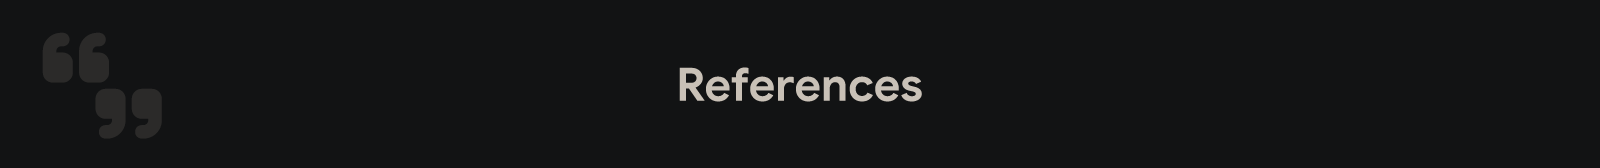

**[1] WorldPop Data**

- Bondarenko, M., Priyatikanto, R., Tejedor-Garavito, N., Zhang, W., McKeen, T., Cunningham, A., Woods, T., Hilton, J., Cihan, D., Nosatiuk, B., Brinkhoff, T., Tatem, A., & Sorichetta, A. (2025). *Constrained estimates of 2015–2030 total number of people per grid square at a resolution of 3 arc (approximately 100 m at the equator), R2024B version v1.* Global Demographic Data Project, funded by the Bill & Melinda Gates Foundation (INV-045237). WorldPop, School of Geography and Environmental Science, University of Southampton. https://doi.org/10.5258/SOTON/WP00803

- Bondarenko, M., Priyatikanto, R., Tejedor-Garavito, N., Zhang, W., McKeen, T., Cunningham, A., Woods, T., Hilton, J., Cihan, D., Nosatiuk, B., Brinkhoff, T., Tatem, A., & Sorichetta, A. (2025). *Constrained estimates of 2015–2030 total number of people per grid square broken down by gender and age groupings at a resolution of 3 arc (approximately 100 m at the equator), R2024B version v1.* WorldPop, University of Southampton. https://doi.org/10.5258/SOTON/WP00805 *(cite only if the age/sex data are used)*

**[2] Software and Services**

- Gorelick, N., Hancher, M., Dixon, M., Ilyushchenko, S., Thau, D., Moore, R., 2017. Google Earth Engine: Planetary-scale geospatial analysis for everyone. Remote Sens. Environ. 202, 18–27. https://doi.org/10.1016/j.rse.2017.06.031

- Samapriya Roy. (2025). samapriya/geeup: geeup: Simple CLI for Earth Engine Uploads (Version 2.0.0) [Computer software]. Zenodo. https://doi.org/10.5281/zenodo.18073520

- The World Bank. (2025). *World Bank Official Boundaries (WBOB)* [Data set]. https://datacatalog.worldbank.org/search/dataset/0038272

- Roy, S., & Priyatikanto, R. *WorldPop Global Population Data 2015–2030.* Awesome GEE Community Catalog. https://gee-community-catalog.org/projects/worldpop/
